# Telangana Cotton Price Forecasting & Price-Spike Alert (Regression + Classification)

**Domain:** Agriculture  **Data:** Agmarknet mandi data via CEDA (Ashoka University) — Telangana cotton, Jan 2024 to Oct 2025

## Problem statement
Cotton prices in Telangana mandis move from week to week, and farmers and traders usually decide when to sell or buy without a reliable forecast. This project uses historical market-level price and arrival data to:
1. **Regression:** predict **next week's modal price** (₹/quintal).
2. **Classification:** predict whether next week's price will **Rise**, **Fall** or stay **Stable** — the **Rise** class is the *price-spike alert*.

## Objectives
1. Clean and merge the raw daily market-level price and arrival files.
2. Aggregate to weekly data and build a composition-adjusted price index.
3. Engineer lag, rolling, arrival and seasonal features (using only past information).
4. Train and compare regression models (Linear, Ridge, Random Forest, XGBoost) against a naive baseline.
5. Train and compare classification models (Logistic Regression, Random Forest, XGBoost) against a majority-class baseline.
6. Evaluate with RMSE / MAE / R² and accuracy / precision / recall / F1, and document insights and limitations.

## 1. Imports

In [1]:
import glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import PowerTransformer
from sklearn.svm import SVR, SVC
from sklearn.model_selection import cross_val_score, validation_curve, KFold
from sklearn.base import clone
from xgboost import XGBRegressor, XGBClassifier

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42

## 2. Load the raw data
The CEDA portal limits each download to 1,000 rows, so the data was downloaded in date windows (`price_*.csv` and `qty_*.csv`, saved under `Cotton/2024` and `Cotton/2025`).

In [2]:
DATA_DIR = "Cotton"

price_files = sorted(glob.glob(f"{DATA_DIR}/**/price_*.csv", recursive=True))
qty_files   = sorted(glob.glob(f"{DATA_DIR}/**/qty_*.csv", recursive=True))
print(len(price_files), "price files,", len(qty_files), "quantity files")

10 price files, 11 quantity files


In [3]:
price_raw = pd.concat([pd.read_csv(f, parse_dates=["t"]) for f in price_files], ignore_index=True)
qty_raw   = pd.concat([pd.read_csv(f, parse_dates=["t"]) for f in qty_files],   ignore_index=True)
print("Raw price rows:", len(price_raw), "| Raw quantity rows:", len(qty_raw))

Raw price rows: 4335 | Raw quantity rows: 4252


In [4]:
price_raw.head()

,t,cmdty,market_id,market_name,state_id,state_name,district_id,district_name,variety,p_min,p_max,p_modal
0,2024-02-14,Cotton,371,Nirmal,36,Telangana,532,Adilabad,Bramha,6785.0,6920.0,6920.0
1,2024-02-14,Cotton,2208,Enkoor,36,Telangana,541,Khammam,Cotton (Unginned),6300.0,6700.0,6630.0
2,2024-02-14,Cotton,389,Kothagudem,36,Telangana,541,Khammam,Cotton (Unginned),6700.0,6920.0,6800.0
3,2024-02-14,Cotton,5,Khammam,36,Telangana,541,Khammam,Cotton (Unginned),5500.0,6625.0,6200.0
4,2024-02-14,Cotton,2786,Narsampet(Nekonda),36,Telangana,540,Warangal,Bramha,6820.0,6920.0,6870.0


In [5]:
qty_raw.head()

,t,cmdty,state_id,state,market_id,market_name,state_name,district_id,district_name,qty
0,2024-02-14,Cotton,36,Telangana,2208,Enkoor,Telangana,541,Khammam,0.01
1,2024-02-14,Cotton,36,Telangana,389,Kothagudem,Telangana,541,Khammam,95.00
2,2024-02-14,Cotton,36,Telangana,5,Khammam,Telangana,541,Khammam,96.70
3,2024-02-14,Cotton,36,Telangana,2786,Narsampet(Nekonda),Telangana,540,Warangal,9.00
4,2024-02-14,Cotton,36,Telangana,1024,Parkal,Telangana,540,Warangal,0.48


## 3. Clean the data
Windows overlap at their edges, so the same record can appear in two files. We remove duplicates, check for missing values and impossible values, and then combine varieties so there is **one row per market per day**.

In [6]:
price = price_raw.drop_duplicates()
qty   = qty_raw.drop_duplicates(subset=["t", "market_id"])
print("Duplicate price rows removed   :", len(price_raw) - len(price))
print("Duplicate quantity rows removed:", len(qty_raw) - len(qty))

Duplicate price rows removed   : 89
Duplicate quantity rows removed: 97


In [7]:
print("\nMissing values in price data:")
print(price[["p_min", "p_max", "p_modal"]].isna().sum())


Missing values in price data:
p_min      8
p_max      9
p_modal    0
dtype: int64


In [8]:
print("\nRows where min > max:", (price.p_min > price.p_max).sum())
print("Date range:", price.t.min().date(), "to", price.t.max().date())


Rows where min > max: 0
Date range: 2024-01-01 to 2025-10-30


In [9]:
price.info()

<class 'pandas.DataFrame'>
Index: 4246 entries, 0 to 4334
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   t              4246 non-null   datetime64[us]
 1   cmdty          4246 non-null   str           
 2   market_id      4246 non-null   int64         
 3   market_name    4246 non-null   str           
 4   state_id       4246 non-null   int64         
 5   state_name     4246 non-null   str           
 6   district_id    4246 non-null   int64         
 7   district_name  4246 non-null   str           
 8   variety        4246 non-null   str           
 9   p_min          4238 non-null   float64       
 10  p_max          4237 non-null   float64       
 11  p_modal        4246 non-null   float64       
dtypes: datetime64[us](1), float64(3), int64(3), str(5)
memory usage: 631.2 KB


In [10]:
qty.info()

<class 'pandas.DataFrame'>
Index: 4155 entries, 0 to 4251
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   t              4155 non-null   datetime64[us]
 1   cmdty          4155 non-null   str           
 2   state_id       4155 non-null   int64         
 3   state          4155 non-null   str           
 4   market_id      4155 non-null   int64         
 5   market_name    4155 non-null   str           
 6   state_name     4155 non-null   str           
 7   district_id    4155 non-null   int64         
 8   district_name  4155 non-null   str           
 9   qty            4155 non-null   float64       
dtypes: datetime64[us](1), float64(1), int64(3), str(5)
memory usage: 525.9 KB


In [11]:
price[["p_min", "p_max", "p_modal"]].describe().round(0)

,p_min,p_max,p_modal
count,4238.0,4237.0,4246.0
mean,6500.0,7082.0,6929.0
std,735.0,389.0,442.0
min,3011.0,4041.0,4000.0
25%,6028.0,6850.0,6630.0
50%,6620.0,7020.0,6920.0
75%,7020.0,7421.0,7300.0
max,8300.0,10322.0,9000.0


In [12]:
print("\nQUANTITY DATA (arrivals)")
print(qty[["qty"]].describe().round(1))


QUANTITY DATA (arrivals)
          qty
count  4155.0
mean    173.2
std     582.4
min       0.0
25%       2.4
50%      14.6
75%      78.0
max    6900.0


In [13]:
print(price["market_name"].value_counts().head(5))   # busiest markets

market_name
Jammikunta    611
Khammam       298
Warangal      269
Adilabad      219
Kesamudram    202
Name: count, dtype: int64


In [14]:
print(price["variety"].value_counts())               # cotton varieties

variety
Cotton (Unginned)    3613
Bramha                424
Cotton (Ginned)       106
MECH-1                 56
RCH-2                  36
Desi                   11
Name: count, dtype: int64


In [15]:
# One row per market per day (average over the cotton varieties traded that day), then attach arrivals
market_day = (price.groupby(["t", "market_id", "market_name"])[["p_min", "p_max", "p_modal"]]
                   .mean().reset_index())
market_day = market_day.merge(qty[["t", "market_id", "qty"]], on=["t", "market_id"], how="left")

In [16]:
# Week ending Sunday
market_day["week"] = market_day.t.dt.to_period("W-SUN").dt.end_time.dt.normalize()

print("Market-day rows:", len(market_day), "| markets:", market_day.market_id.nunique())

Market-day rows: 4228 | markets: 49


In [17]:
print("Share of market-days with an arrival record:", round(market_day.qty.notna().mean(), 3))

Share of market-days with an arrival record: 0.946


In [18]:
market_day.head()

,t,market_id,market_name,p_min,p_max,p_modal,qty,week
0,2024-01-01,889,Burgampadu,6800.0,7020.0,6900.0,5.0,2024-01-07
1,2024-01-01,971,Laxettipet,6879.0,7020.0,6949.0,85.0,2024-01-07
2,2024-01-01,982,Mancharial,7020.0,7020.0,7020.0,32.0,2024-01-07
3,2024-01-02,19,Warangal,6000.0,6600.0,6500.0,352.9,2024-01-07
4,2024-01-02,400,Kesamudram,3108.0,6769.0,6525.0,43.8,2024-01-07


## 4. Weekly table

In [19]:
g = market_day.groupby("week")
weekly = pd.DataFrame({
    "n_markets": g.market_id.nunique(),     # markets reporting that week
    "n_days":    g.t.nunique(),             # days with data that week
    "qty":       g.qty.sum(min_count=1),    # total arrivals (tonnes)
})

In [20]:
# Reindex so every calendar week is present
all_weeks = pd.date_range(weekly.index.min(), weekly.index.max(), freq="W-SUN")
weekly = weekly.reindex(all_weeks)
weekly.index.name = "week"
print("Weeks with no price data at all:", list(weekly.index[weekly.n_markets.isna()].date))

weekly["interpolated"] = weekly.n_markets.isna().astype(int)   # flag for filled weeks
weekly[["n_markets", "n_days"]] = weekly[["n_markets", "n_days"]].fillna(0)
weekly["qty"] = weekly.qty.fillna(0)    # no arrival records = off-season / no trade recorded

Weeks with no price data at all: [datetime.date(2024, 12, 22)]


In [21]:
# Drop a trailing partial week (the data ends on 30 Oct 2025)
if weekly.n_days.iloc[-1] < 5:
    weekly = weekly.iloc[:-1]
print("Weekly rows:", len(weekly), "|", weekly.index.min().date(), "to", weekly.index.max().date())

Weekly rows: 95 | 2024-01-07 to 2025-10-26


In [22]:
weekly.head()

,n_markets,n_days,qty,interpolated
week,,,,
2024-01-07,30.0,7.0,25193.81,0
2024-01-14,29.0,7.0,33334.44,0
2024-01-21,27.0,7.0,19201.26,0
2024-01-28,33.0,7.0,27776.67,0
2024-02-04,36.0,7.0,29150.69,0


### Composition-adjusted weekly price
The number of markets reporting changes a lot from week to week (from 2 to 36), and markets have different price levels. A plain weekly average would jump just because a *different mix of markets* reported. To avoid that, each market's price is divided by that market's own average price, the ratios are averaged across markets each week, and the result is scaled back to ₹/quintal.

To avoid using future information, each market's average comes **only from the training period** (the first 70% of weeks).

In [23]:
TRAIN_FRAC = 0.70
TRAIN_END = weekly.index[int(len(weekly) * TRAIN_FRAC) - 1]
print("Training period ends:", TRAIN_END.date())

Training period ends: 2025-04-06


In [24]:
train_md = market_day[market_day.t <= TRAIN_END]
market_base = train_md.groupby("market_id").p_modal.mean()   # each market's normal price level
overall_base = train_md.p_modal.mean()

adj = market_day[market_day.market_id.isin(market_base.index)].copy()
for c in ["p_min", "p_max", "p_modal"]:
    adj[c] = adj[c] / adj.market_id.map(market_base)

index_df = adj.groupby("week")[["p_min", "p_max", "p_modal"]].mean() * overall_base
weekly[["p_min", "p_max", "p_modal"]] = index_df.reindex(weekly.index)
weekly[["p_min", "p_max", "p_modal"]] = weekly[["p_min", "p_max", "p_modal"]].interpolate()
weekly.round(1).head()

,n_markets,n_days,qty,interpolated,p_min,p_max,p_modal
week,,,,,,,
2024-01-07,30.0,7.0,25193.8,0,6278.7,6773.5,6664.9
2024-01-14,29.0,7.0,33334.4,0,6245.7,6766.6,6652.0
2024-01-21,27.0,7.0,19201.3,0,6350.4,6765.3,6655.5
2024-01-28,33.0,7.0,27776.7,0,6420.0,6784.6,6703.7
2024-02-04,36.0,7.0,29150.7,0,6300.7,6733.1,6643.2


## 5. Exploratory data analysis

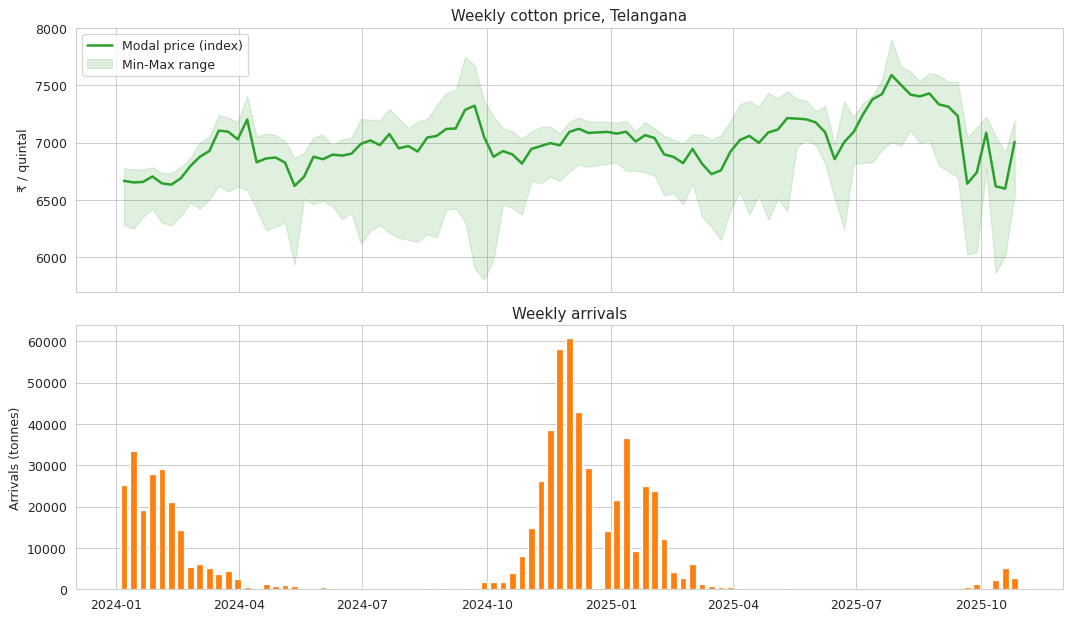

In [25]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(weekly.index, weekly.p_modal, color="tab:green", lw=2, label="Modal price (index)")
ax[0].fill_between(weekly.index, weekly.p_min, weekly.p_max, color="tab:green", alpha=0.15, label="Min-Max range")
ax[0].set_ylabel("₹ / quintal"); ax[0].set_title("Weekly cotton price, Telangana"); ax[0].legend()
ax[1].bar(weekly.index, weekly.qty, width=5, color="tab:orange")
ax[1].set_ylabel("Arrivals (tonnes)"); ax[1].set_title("Weekly arrivals")
plt.tight_layout(); plt.show()

Correlation between price and arrivals: -0.174


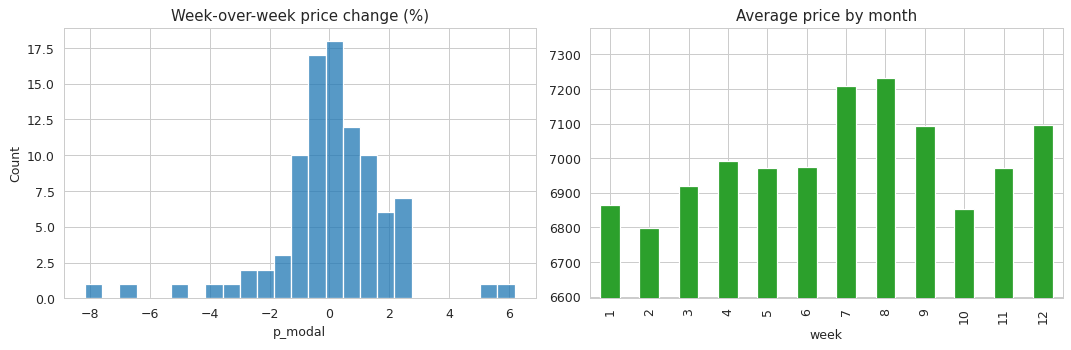

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(weekly.p_modal.pct_change().dropna() * 100, bins=25, ax=ax[0], color="tab:blue")
ax[0].set_title("Week-over-week price change (%)")
monthly = weekly.groupby(weekly.index.month).agg(price=("p_modal", "mean"), arrivals=("qty", "mean"))
monthly.price.plot(kind="bar", ax=ax[1], color="tab:green"); ax[1].set_title("Average price by month")
ax[1].set_ylim(monthly.price.min() * 0.97, monthly.price.max() * 1.02)
plt.tight_layout(); plt.show()
print("Correlation between price and arrivals:", round(weekly.p_modal.corr(weekly.qty), 3))

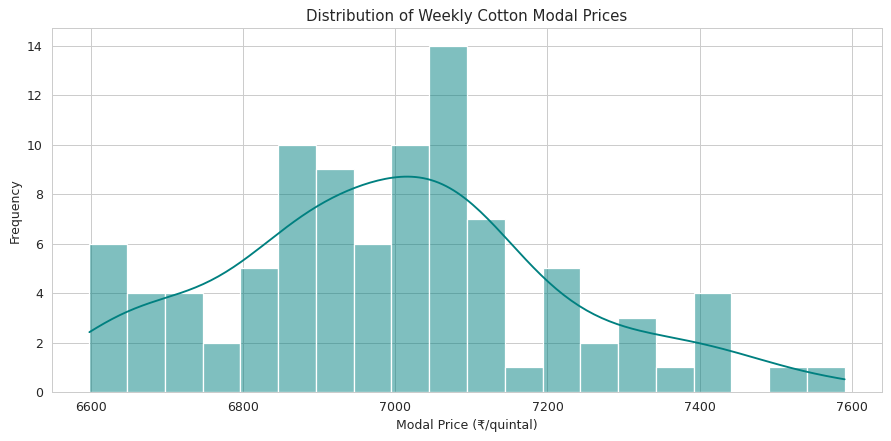

In [27]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=weekly,
    x="p_modal",
    bins=20,
    kde=True,
    color="teal"
)

plt.title("Distribution of Weekly Cotton Modal Prices")
plt.xlabel("Modal Price (₹/quintal)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

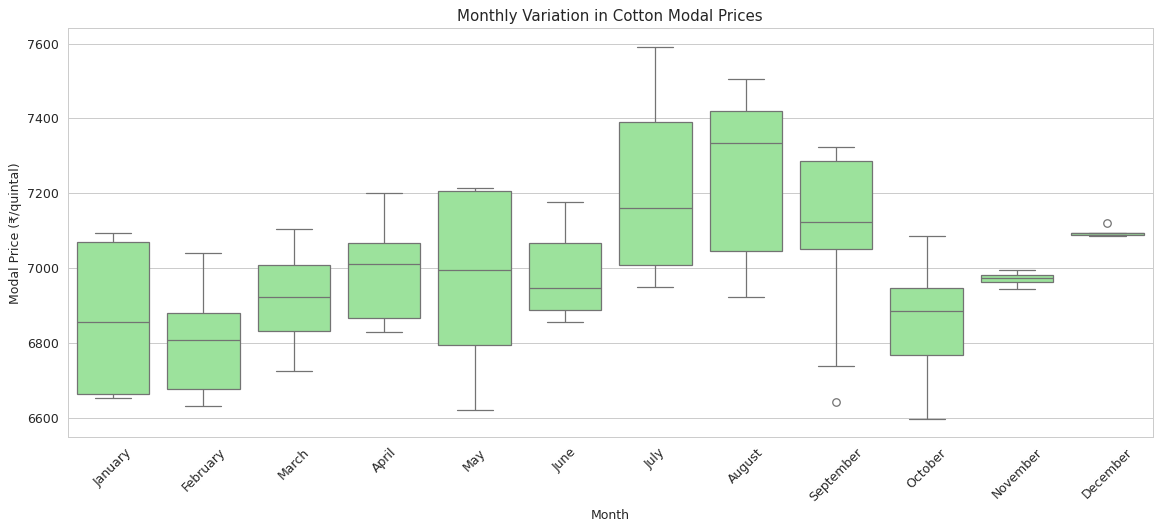

In [28]:
weekly_eda = weekly.copy()
weekly_eda["month"] = weekly_eda.index.month_name()

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=weekly_eda,
    x="month",
    y="p_modal",
    order=month_order,
    color="lightgreen"
)

plt.title("Monthly Variation in Cotton Modal Prices")
plt.xlabel("Month")
plt.ylabel("Modal Price (₹/quintal)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

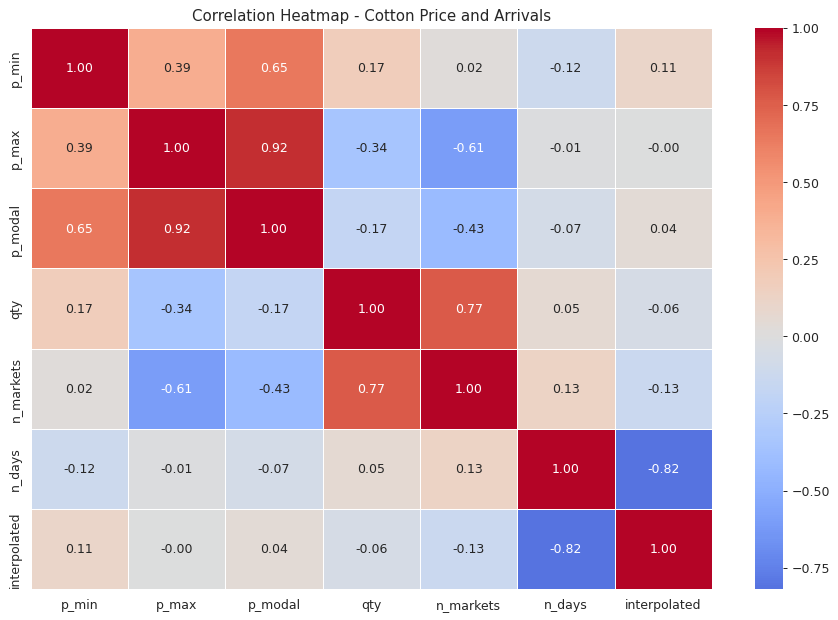

In [29]:
plt.figure(figsize=(10, 7))

corr = weekly[
    ["p_min", "p_max", "p_modal", "qty",
     "n_markets", "n_days", "interpolated"]
].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap - Cotton Price and Arrivals")
plt.tight_layout()
plt.show()

## 6. Feature engineering and targets
Every feature uses only information available **at or before the current week**.

| Group | Features |
|---|---|
| Current price | modal, min, max, spread (max - min) |
| Lags | modal price 1, 2, 3 and 4 weeks ago (lag 3 is already implied by the 4-week rolling mean, but is kept) |
| Trend / volatility | 4-week rolling mean and std, 1-week and 4-week % change |
| Arrivals | arrivals, 1- and 2-week lags, 1-week % change |
| Market | number of markets reporting |
| Calendar | month, week of year, peak-season flag (Oct-Mar) |
| Data quality | interpolated-week flag |

**Targets**
- Regression: `next_price` = next week's modal price.
- Classification: `move` = Rise if next week's change is above +1%, Fall if below -1%, otherwise Stable. The ±1% threshold was chosen so that none of the classes is nearly empty (a ±3% threshold leaves only about 5% Rise and 5% Fall weeks).

In [30]:
f = pd.DataFrame(index=weekly.index)
f["modal"]  = weekly.p_modal
f["min"]    = weekly.p_min
f["max"]    = weekly.p_max
f["spread"] = weekly.p_max - weekly.p_min
for k in (1, 2, 3, 4):
    f[f"modal_lag{k}"] = weekly.p_modal.shift(k)
f["roll_mean4"] = weekly.p_modal.rolling(4).mean()
f["roll_std4"]  = weekly.p_modal.rolling(4).std()
f["pct_chg1"]   = weekly.p_modal.pct_change(1)
f["pct_chg4"]   = weekly.p_modal.pct_change(4)
f["qty"]        = weekly.qty
f["qty_lag1"]   = weekly.qty.shift(1)
f["qty_lag2"]   = weekly.qty.shift(2)
f["qty_chg1"]   = (weekly.qty - weekly.qty.shift(1)) / (weekly.qty.shift(1) + 1)
f["n_markets"]  = weekly.n_markets
f["month"]      = weekly.index.month
f["weekofyear"] = weekly.index.isocalendar().week.astype(int).values
f["peak_season"] = weekly.index.month.isin([10, 11, 12, 1, 2, 3]).astype(int)
f["interpolated"] = weekly.interpolated

In [31]:
THRESHOLD = 0.01   # +/-1 %
FEATURES = list(f.columns)

# Targets (looking one week ahead)
f["next_price"] = weekly.p_modal.shift(-1)
f["next_chg"]   = f.next_price / f.modal - 1
f["move"] = np.where(f.next_chg > THRESHOLD, "Rise", np.where(f.next_chg < -THRESHOLD, "Fall", "Stable"))

In [32]:
latest = f.iloc[[-1]]                                  # last week: used later for a live forecast
data = f.dropna(subset=FEATURES + ["next_price"])      # rows with full history AND a known next week
print("Usable rows:", len(data), "| features:", len(FEATURES))
print(data.move.value_counts())

Usable rows: 90 | features: 21
move
Stable    47
Rise      25
Fall      18
Name: count, dtype: int64


In [33]:
pd.set_option('display.max_columns',None)
display(
data[FEATURES + ["next_price", "move"]].head())

,modal,min,max,spread,modal_lag1,modal_lag2,modal_lag3,modal_lag4,roll_mean4,roll_std4,pct_chg1,pct_chg4,qty,qty_lag1,qty_lag2,qty_chg1,n_markets,month,weekofyear,peak_season,interpolated,next_price,move
week,,,,,,,,,,,,,,,,,,,,,,,
2024-02-04,6643.172783,6300.733410,6733.113700,432.380291,6703.712884,6655.502562,6652.046725,6664.865737,6663.608738,27.235767,-0.009031,-0.003255,29150.69,27776.67,19201.26,0.049465,36.0,2,5,1,0,6632.452583,Stable
2024-02-11,6632.452583,6275.352049,6731.686456,456.334407,6643.172783,6703.712884,6655.502562,6652.046725,6658.710203,31.445213,-0.001614,-0.002946,21127.91,29150.69,27776.67,-0.275208,32.0,2,6,1,0,6688.226481,Stable
2024-02-18,6688.226481,6359.166321,6787.916941,428.750620,6632.452583,6643.172783,6703.712884,6655.502562,6666.891183,34.446152,0.008409,0.004917,14440.46,21127.91,29150.69,-0.316507,30.0,2,7,1,0,6794.249945,Rise
2024-02-25,6794.249945,6476.502888,6864.467884,387.964996,6688.226481,6632.452583,6643.172783,6703.712884,6689.525448,73.880058,0.015852,0.013506,5278.19,14440.46,21127.91,-0.634442,27.0,2,8,1,0,6875.801090,Rise
2024-03-03,6875.801090,6422.058298,7002.465087,580.406789,6794.249945,6688.226481,6632.452583,6643.172783,6747.682525,108.621441,0.012003,0.035018,6165.19,5278.19,14440.46,0.168018,27.0,3,9,1,0,6926.334973,Stable


## 7. Train / test split (by time)
The data is a time series, so we **never shuffle**: models train on earlier weeks and are tested on later weeks they have never seen.

In [34]:
train = data[data.index < TRAIN_END]
test  = data[data.index >= TRAIN_END]
X_train, X_test = train[FEATURES], test[FEATURES]
print("Train:", train.index.min().date(), "to", train.index.max().date(), f"({len(train)} weeks)")
print("Test :", test.index.min().date(),  "to", test.index.max().date(),  f"({len(test)} weeks)")
print("\nClass counts  train:", train.move.value_counts().to_dict())
print("Class counts  test :", test.move.value_counts().to_dict())
tscv = TimeSeriesSplit(n_splits=4)   # for hyper-parameter tuning inside the training set

Train: 2024-02-04 to 2025-03-30 (61 weeks)
Test : 2025-04-06 to 2025-10-19 (29 weeks)

Class counts  train: {'Stable': 36, 'Rise': 15, 'Fall': 10}
Class counts  test : {'Stable': 11, 'Rise': 10, 'Fall': 8}


### 7.1 Scaling options: standard scaling vs Yeo-Johnson power transform
Linear, Ridge, Logistic and SVM models work best when features are roughly symmetric and on the same scale. Two options are compared:
- **Standard scaling** (`StandardScaler`): subtract the mean, divide by the standard deviation.
- **Yeo-Johnson power transform** (`PowerTransformer`): reshapes skewed features towards a bell shape, then standardizes them. Box-Cox would fail here because it needs strictly positive values, and some features are negative or zero (% changes, arrivals in off-season weeks).

Both are placed **inside the model pipeline**, so they are fitted on the training weeks only (no leakage). Flag and calendar columns are only scaled, not transformed. Random Forest and XGBoost are not affected by monotonic transformations, so they do not use it.

In [35]:
flags = ["interpolated", "peak_season", "month", "weekofyear"]   # 0/1 or calendar columns: only scaled
cont  = [c for c in FEATURES if c not in flags]                  # continuous columns: power-transformed

def yeo():
    """Yeo-Johnson on continuous features + scaling of the flag columns."""
    return ColumnTransformer([("pt", PowerTransformer(method="yeo-johnson"), cont),
                              ("sc", StandardScaler(), flags)])

# Skewness of each continuous feature, before and after the transform (training data only)
after = pd.DataFrame(PowerTransformer(method="yeo-johnson").fit_transform(X_train[cont]), columns=cont)
pd.DataFrame({"skew before": X_train[cont].skew().values, "skew after": after.skew().values}, index=cont).round(2)

,skew before,skew after
modal,-0.08,-0.00
min,-0.31,-0.04
max,0.77,0.13
spread,1.22,0.08
modal_lag1,-0.07,-0.00
modal_lag2,-0.11,-0.00
modal_lag3,-0.15,-0.00
modal_lag4,-0.18,-0.01
roll_mean4,-0.35,-0.03
roll_std4,0.92,-0.03


## 8. Regression — predict next week's modal price
Baseline: the **naive forecast** (next week's price = this week's price). A model is only useful if it beats it.

In [36]:
def rmse(y, p): return float(np.sqrt(mean_squared_error(y, p)))

y_train, y_test = train.next_price, test.next_price

In [37]:
def make_svr(prep):
    """SVR needs a scaled target too (prices are around 7,000), so the target is standardized."""
    return GridSearchCV(
        TransformedTargetRegressor(regressor=make_pipeline(prep, SVR()), transformer=StandardScaler()),
        {"regressor__svr__C": [0.1, 1, 10], "regressor__svr__epsilon": [0.05, 0.1, 0.3],
         "regressor__svr__gamma": ["scale", 0.01]},
        cv=tscv, scoring="neg_root_mean_squared_error")

def make_ridge(prep):
    return GridSearchCV(make_pipeline(prep, Ridge()), {"ridge__alpha": [1, 10, 100]},
                        cv=tscv, scoring="neg_root_mean_squared_error")

reg_models = {
    "Linear Regression":              make_pipeline(StandardScaler(), LinearRegression()),
    "Linear Regression + Yeo-Johnson": make_pipeline(yeo(), LinearRegression()),
    "Ridge":                          make_ridge(StandardScaler()),
    "Ridge + Yeo-Johnson":            make_ridge(yeo()),
    "SVR":                            make_svr(StandardScaler()),
    "SVR + Yeo-Johnson":              make_svr(yeo()),
    "Random Forest": GridSearchCV(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
                                  {"max_depth": [3, 5], "min_samples_leaf": [3, 5]}, cv=tscv,
                                  scoring="neg_root_mean_squared_error"),
    "XGBoost": GridSearchCV(XGBRegressor(learning_rate=0.05, subsample=0.8, random_state=RANDOM_STATE),
                            {"max_depth": [2, 3], "n_estimators": [100, 200]}, cv=tscv,
                            scoring="neg_root_mean_squared_error"),
}

In [38]:
reg_pred, reg_pred_train = {"Naive baseline": test.modal.values}, {"Naive baseline": train.modal.values}
for name, model in reg_models.items():
    model.fit(X_train, y_train)
    reg_pred[name] = model.predict(X_test)
    reg_pred_train[name] = model.predict(X_train)      # kept for the overfitting check below

### Best hyperparameters found by time-series cross-validation

In [39]:
for name, model in reg_models.items():
    if hasattr(model, "best_params_"):
        print(f"{name:34s} {model.best_params_}")

Ridge                              {'ridge__alpha': 100}
Ridge + Yeo-Johnson                {'ridge__alpha': 100}
SVR                                {'regressor__svr__C': 1, 'regressor__svr__epsilon': 0.3, 'regressor__svr__gamma': 0.01}
SVR + Yeo-Johnson                  {'regressor__svr__C': 1, 'regressor__svr__epsilon': 0.3, 'regressor__svr__gamma': 0.01}
Random Forest                      {'max_depth': 5, 'min_samples_leaf': 5}
XGBoost                            {'max_depth': 2, 'n_estimators': 100}


In [40]:
reg_results = pd.DataFrame({
    name: {"RMSE": rmse(y_test, p), "MAE": mean_absolute_error(y_test, p), "R²": r2_score(y_test, p)}
    for name, p in reg_pred.items()
}).T.round(3)
reg_results

,RMSE,MAE,R²
Naive baseline,193.685,129.440,0.440
Linear Regression,172.802,133.442,0.555
Linear Regression + Yeo-Johnson,163.110,120.760,0.603
Ridge,207.714,178.721,0.356
Ridge + Yeo-Johnson,204.111,175.733,0.379
SVR,239.708,204.959,0.143
SVR + Yeo-Johnson,243.285,209.642,0.117
Random Forest,244.694,206.283,0.107
XGBoost,230.421,192.053,0.208


In [41]:
best_reg = reg_results.drop("Naive baseline")["RMSE"].idxmin()
print("Best regression model by RMSE:", best_reg)

Best regression model by RMSE: Linear Regression + Yeo-Johnson


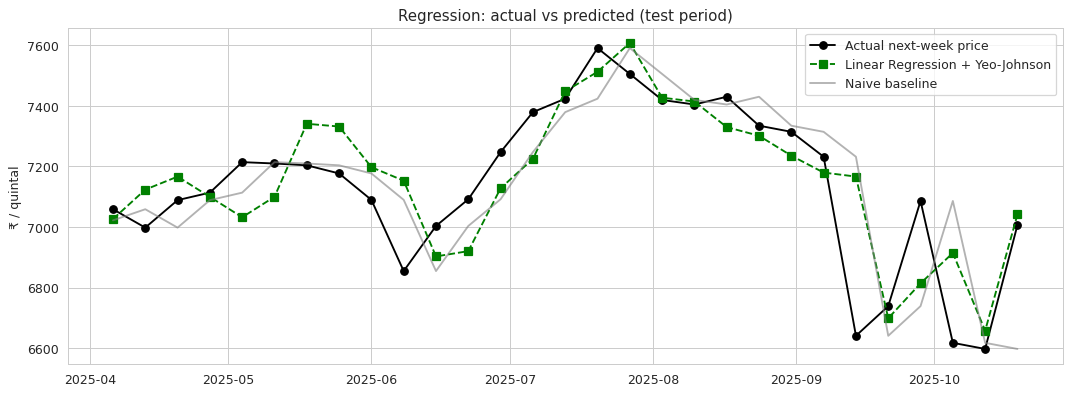

In [42]:
plt.figure(figsize=(12, 4.5))
plt.plot(test.index, y_test, "k-o", label="Actual next-week price")
plt.plot(test.index, reg_pred[best_reg], "g--s", label=f"{best_reg}")
plt.plot(test.index, reg_pred["Naive baseline"], color="gray", alpha=0.6, label="Naive baseline")
plt.ylabel("₹ / quintal"); plt.title("Regression: actual vs predicted (test period)"); plt.legend()
plt.tight_layout(); plt.show()

### 8.1 Overfitting vs underfitting (training error vs testing error)
- **Underfitting:** the model is too simple. It has a **high error on the training data as well** as on the test data.
- **Overfitting:** the model memorizes the training weeks. Its **training error is low but the test error is much higher**.
- **Good fit:** training and test errors are both low and close to each other.

Rules used here (simple guides, not laws):
- The test months (Apr to Oct 2025) were more volatile than the training months. The **naive baseline has no fitted parameters**, so its test/train error ratio shows how much harder the test period is. A model is judged against that ratio: *Adjusted ratio = (test RMSE / train RMSE) / naive ratio*.
- **Overfit** if the adjusted ratio is above 1.75, **Mild overfit** if it is between 1.3 and 1.75.
- **Underfit** if training R² is below 0.6 (the model cannot even explain 60% of the variation in the weeks it was trained on).
- Otherwise **Good fit**.

In [43]:
naive_ratio = rmse(y_test, reg_pred["Naive baseline"]) / rmse(y_train, reg_pred_train["Naive baseline"])
rows = {}
for name in reg_pred:
    tr_rmse, te_rmse = rmse(y_train, reg_pred_train[name]), rmse(y_test, reg_pred[name])
    tr_r2, te_r2 = r2_score(y_train, reg_pred_train[name]), r2_score(y_test, reg_pred[name])
    adj = (te_rmse / tr_rmse) / naive_ratio
    if name == "Naive baseline":
        verdict = "baseline"
    elif adj > 1.75:
        verdict = "Overfit"
    elif tr_r2 < 0.6:
        verdict = "Underfit"
    elif adj > 1.3:
        verdict = "Mild overfit"
    else:
        verdict = "Good fit"
    rows[name] = {"Train RMSE": tr_rmse, "Test RMSE": te_rmse, "Adjusted ratio": adj,
                  "Train R²": tr_r2, "Test R²": te_r2, "Verdict": verdict}
fit_table = pd.DataFrame(rows).T
fit_table.iloc[:, :5] = fit_table.iloc[:, :5].astype(float).round(2)
fit_table

,Train RMSE,Test RMSE,Adjusted ratio,Train R²,Test R²,Verdict
Naive baseline,104.14,193.69,1.0,0.47,0.44,baseline
Linear Regression,75.76,172.8,1.23,0.72,0.55,Good fit
Linear Regression + Yeo-Johnson,71.59,163.11,1.23,0.75,0.6,Good fit
Ridge,93.38,207.71,1.2,0.58,0.36,Underfit
Ridge + Yeo-Johnson,95.59,204.11,1.15,0.56,0.38,Underfit
SVR,88.24,239.71,1.46,0.62,0.14,Mild overfit
SVR + Yeo-Johnson,88.05,243.28,1.49,0.62,0.12,Mild overfit
Random Forest,70.81,244.69,1.86,0.76,0.11,Overfit
XGBoost,39.98,230.42,3.1,0.92,0.21,Overfit


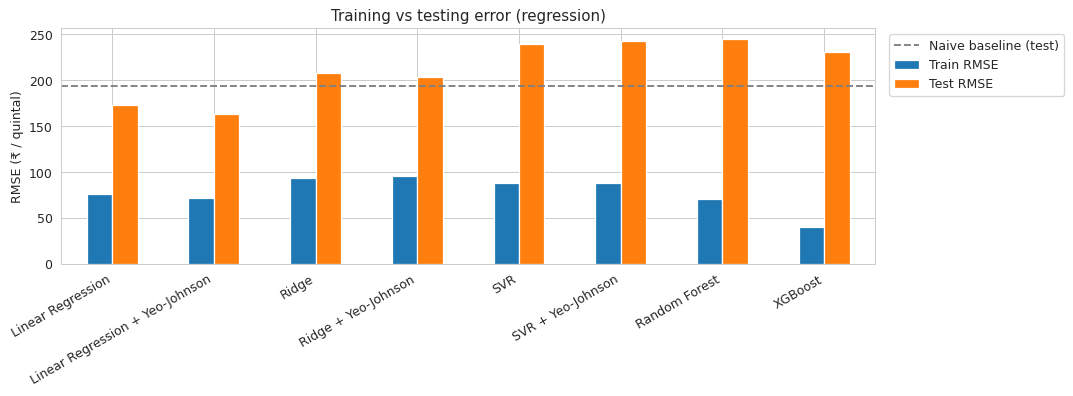

In [44]:
plot_df = fit_table.drop("Naive baseline")[["Train RMSE", "Test RMSE"]].astype(float)
plot_df.plot(kind="bar", figsize=(12, 4.5), color=["tab:blue", "tab:orange"])
plt.axhline(rmse(y_test, reg_pred["Naive baseline"]), color="gray", ls="--", label="Naive baseline (test)")
plt.ylabel("RMSE (₹ / quintal)"); plt.title("Training vs testing error (regression)")
plt.xticks(rotation=30, ha="right"); plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

**Reading the table and chart (this run)**
- **Linear Regression, with and without Yeo-Johnson:** good fit. Training and test errors are both fairly low and the gap is about what the naive baseline also shows.
- **Ridge:** underfit. Its best `alpha` was 100, the largest value tried, so the model was held back too much (a wider grid could be tried).
- **SVR:** mild overfit. **Random Forest and XGBoost:** clear overfit. XGBoost has a training RMSE of about ₹40 but a test RMSE of about ₹230.
- Every model, including the naive baseline, has a higher test error than training error, because the test months were more volatile.

**Model complexity curve.** Random Forest is used to show the idea: as `max_depth` grows the trees can memorize more, so the training error keeps falling while the validation error (time-series CV inside the training period) does not improve. The widening gap between the two lines is overfitting. Here the validation error is lowest for the simplest trees, which suggests the data (61 weeks) is too small and noisy for complex models.

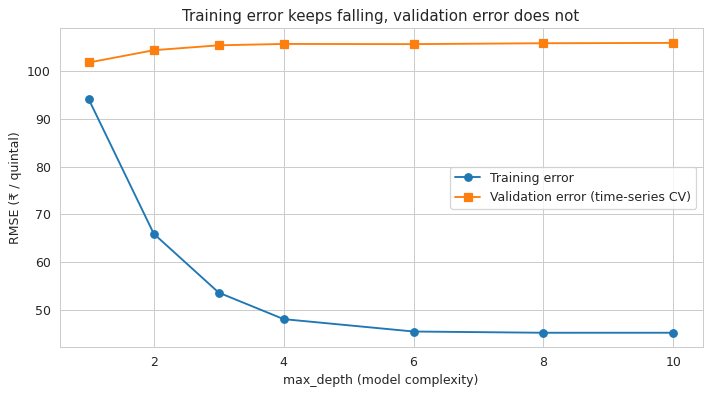

In [45]:
depths = [1, 2, 3, 4, 6, 8, 10]
tr_sc, va_sc = validation_curve(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
                                X_train, y_train, param_name="max_depth", param_range=depths,
                                cv=tscv, scoring="neg_root_mean_squared_error")
plt.figure(figsize=(8, 4.5))
plt.plot(depths, -tr_sc.mean(axis=1), "o-", label="Training error")
plt.plot(depths, -va_sc.mean(axis=1), "s-", label="Validation error (time-series CV)")
plt.xlabel("max_depth (model complexity)"); plt.ylabel("RMSE (₹ / quintal)")
plt.title("Training error keeps falling, validation error does not"); plt.legend(); plt.tight_layout(); plt.show()

### 8.2 Time-series cross-validation
A single train/test split can be lucky or unlucky. Time-series cross-validation repeats the test several times: each round trains on earlier weeks and validates on the next 6 weeks (`TimeSeriesSplit`), moving forward in time. It is the only kind of cross-validation used for model tuning (`GridSearchCV(cv=tscv)`) in this notebook.

Here it is also used to check how stable each model is on the training period. The tuned settings of each model are reused (so this is slightly optimistic for the tuned models).

In [46]:
ts_cv = TimeSeriesSplit(n_splits=5, test_size=6)
print("Training weeks per fold:", [len(a) for a, _ in ts_cv.split(X_train)])

cv_rows = {}
naive = [rmse(y_train.iloc[v], X_train.modal.iloc[v]) for _, v in ts_cv.split(X_train)]
cv_rows["Naive baseline"] = (np.mean(naive), np.std(naive))
for name, model in reg_models.items():
    est = clone(model.best_estimator_) if hasattr(model, "best_estimator_") else clone(model)
    s = -cross_val_score(est, X_train, y_train, cv=ts_cv, scoring="neg_root_mean_squared_error")
    cv_rows[name] = (s.mean(), s.std())

cv_table = pd.DataFrame(cv_rows, index=["CV RMSE (mean)", "CV RMSE (std)"]).T
cv_table["Test RMSE"] = [rmse(y_test, reg_pred[n]) for n in cv_table.index]
cv_table.round(1)

Training weeks per fold: [31, 37, 43, 49, 55]


,CV RMSE (mean),CV RMSE (std),Test RMSE
Naive baseline,88.4,43.2,193.7
Linear Regression,829.5,1166.4,172.8
Linear Regression + Yeo-Johnson,187.0,67.7,163.1
Ridge,191.8,173.6,207.7
Ridge + Yeo-Johnson,93.2,32.7,204.1
SVR,110.8,22.3,239.7
SVR + Yeo-Johnson,91.6,33.9,243.3
Random Forest,97.3,47.4,244.7
XGBoost,106.2,42.8,230.4


**How to read this:** a low mean and a small standard deviation mean the model is reliable across different periods. A large standard deviation means the model is unstable (it works in some periods and fails in others). Compare every model with the **naive baseline on the same folds**: a model that cannot beat it in CV has not shown a real advantage.

### 8.3 Why not ordinary K-fold?
Ordinary (shuffled) K-fold mixes weeks from all periods, so the model is trained on weeks that come *after* the weeks it is validated on. Neighbouring weeks have almost the same price, so the model effectively sees the answer, and the estimate answers the wrong question ("how well can I fill in a missing week?" instead of "how well can I forecast the future?"). The next cell compares the two. The leaky estimate can look better (as for the linear model) or about the same; in either case it is not a trustworthy measure. It is shown only as a demonstration and is **not used for model selection**.

In [47]:
demo = {}
for name in ["Linear Regression + Yeo-Johnson", "Ridge + Yeo-Johnson"]:
    est = clone(reg_models[name].best_estimator_) if hasattr(reg_models[name], "best_estimator_") else clone(reg_models[name])
    t = -cross_val_score(est, X_train, y_train, cv=ts_cv, scoring="neg_root_mean_squared_error")
    k = -cross_val_score(est, X_train, y_train, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                         scoring="neg_root_mean_squared_error")
    demo[name] = {"Time-series CV RMSE": t.mean(), "Shuffled K-fold RMSE (leaky)": k.mean()}
pd.DataFrame(demo).T.round(1)

,Time-series CV RMSE,Shuffled K-fold RMSE (leaky)
Linear Regression + Yeo-Johnson,187.0,145.4
Ridge + Yeo-Johnson,93.2,101.7


## 9. Classification — Rise / Fall / Stable (price-spike alert)
Baseline: always predict the most common class (**Stable**). Class weights are balanced so the models do not simply predict Stable.

In [48]:
y_train_c, y_test_c = train.move, test.move
classes = ["Fall", "Stable", "Rise"]
enc = {c: i for i, c in enumerate(classes)}
dec = {i: c for c, i in enc.items()}

def make_logit(prep):
    return make_pipeline(prep, LogisticRegression(max_iter=3000, class_weight="balanced"))

clf_models = {
    "Logistic Regression":               make_logit(StandardScaler()),
    "Logistic Regression + Yeo-Johnson": make_logit(yeo()),
    "SVC": GridSearchCV(make_pipeline(StandardScaler(), SVC(class_weight="balanced")),
                        {"svc__C": [0.1, 1, 10], "svc__gamma": ["scale", 0.01]},
                        cv=tscv, scoring="f1_macro"),
    "Random Forest": GridSearchCV(RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                         random_state=RANDOM_STATE),
                                  {"max_depth": [3, 5], "min_samples_leaf": [3, 5]}, cv=tscv,
                                  scoring="f1_macro"),
}
clf_pred = {"Majority baseline": np.array(["Stable"] * len(test))}
clf_pred_train = {"Majority baseline": np.array(["Stable"] * len(train))}
for name, model in clf_models.items():
    model.fit(X_train, y_train_c)
    clf_pred[name] = model.predict(X_test)
    clf_pred_train[name] = model.predict(X_train)

# XGBoost needs numeric labels (fixed settings; a CV fold can lack a class)
xgb_clf = XGBClassifier(n_estimators=150, max_depth=3, learning_rate=0.05, subsample=0.8,
                        random_state=RANDOM_STATE)
xgb_clf.fit(X_train, y_train_c.map(enc))
clf_pred["XGBoost"] = pd.Series(xgb_clf.predict(X_test)).map(dec).values
clf_pred_train["XGBoost"] = pd.Series(xgb_clf.predict(X_train)).map(dec).values

def clf_scores(y, p):
    return {"Accuracy": accuracy_score(y, p),
            "Precision (macro)": precision_score(y, p, average="macro", zero_division=0),
            "Recall (macro)": recall_score(y, p, average="macro", zero_division=0),
            "F1 (macro)": f1_score(y, p, average="macro", zero_division=0)}

clf_results = pd.DataFrame({n: clf_scores(y_test_c, p) for n, p in clf_pred.items()}).T.round(3)
clf_results

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Majority baseline,0.379,0.126,0.333,0.183
Logistic Regression,0.448,0.604,0.468,0.432
Logistic Regression + Yeo-Johnson,0.414,0.477,0.404,0.388
SVC,0.448,0.611,0.480,0.424
Random Forest,0.483,0.349,0.504,0.412
XGBoost,0.448,0.633,0.442,0.399


### 9.1 Overfitting vs underfitting for the classifiers
Same idea as for regression, using macro F1: *Underfit* if training F1 < 0.5; *Overfit* if training F1 is more than 0.4 above test F1; *Mild overfit* if the gap is between 0.2 and 0.4; otherwise *Good fit*. With only 61 training weeks and 29 test weeks, a gap of 0.2 to 0.3 is normal noise, so only large gaps are treated as clear overfitting.

In [49]:
rows = {}
for name in clf_pred:
    trf = f1_score(y_train_c, clf_pred_train[name], average="macro", zero_division=0)
    tef = f1_score(y_test_c, clf_pred[name], average="macro", zero_division=0)
    tra, tea = accuracy_score(y_train_c, clf_pred_train[name]), accuracy_score(y_test_c, clf_pred[name])
    if name == "Majority baseline":
        verdict = "baseline"
    elif trf < 0.5:
        verdict = "Underfit"
    elif trf - tef > 0.4:
        verdict = "Overfit"
    elif trf - tef > 0.2:
        verdict = "Mild overfit"
    else:
        verdict = "Good fit"
    rows[name] = {"Train accuracy": tra, "Test accuracy": tea, "Train F1": trf, "Test F1": tef,
                  "F1 gap (train - test)": trf - tef, "Verdict": verdict}
clf_fit_table = pd.DataFrame(rows).T
clf_fit_table.iloc[:, :5] = clf_fit_table.iloc[:, :5].astype(float).round(3)
clf_fit_table

,Train accuracy,Test accuracy,Train F1,Test F1,F1 gap (train - test),Verdict
Majority baseline,0.59,0.379,0.247,0.183,0.064,baseline
Logistic Regression,0.705,0.448,0.696,0.432,0.265,Mild overfit
Logistic Regression + Yeo-Johnson,0.672,0.414,0.657,0.388,0.269,Mild overfit
SVC,0.689,0.448,0.678,0.424,0.254,Mild overfit
Random Forest,0.967,0.483,0.964,0.412,0.552,Overfit
XGBoost,1.0,0.448,1.0,0.399,0.601,Overfit


Best classification model by macro F1: Logistic Regression
              precision    recall  f1-score   support

        Fall       0.43      0.75      0.55         8
      Stable       0.38      0.45      0.42        11
        Rise       1.00      0.20      0.33        10

    accuracy                           0.45        29
   macro avg       0.60      0.47      0.43        29
weighted avg       0.61      0.45      0.42        29



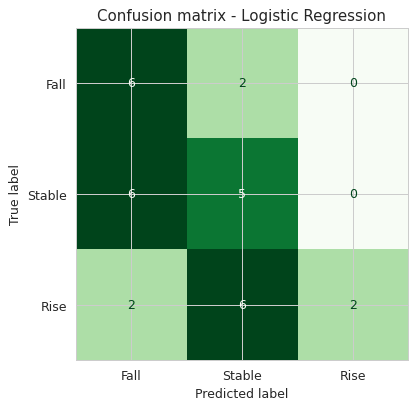

In [50]:
best_clf = clf_results.drop("Majority baseline")["F1 (macro)"].idxmax()
print("Best classification model by macro F1:", best_clf)
print(classification_report(y_test_c, clf_pred[best_clf], labels=classes, zero_division=0))

cm = confusion_matrix(y_test_c, clf_pred[best_clf], labels=classes)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap="Greens", colorbar=False)
plt.title(f"Confusion matrix - {best_clf}"); plt.show()

## 10. Price-spike alert
The alert fires when the model predicts **Rise**. We check how often an alert is right (precision) and how many real rises it catches (recall).

In [51]:
alert_pred = (clf_pred[best_clf] == "Rise")
alert_true = (y_test_c.values == "Rise")
tp = int((alert_pred & alert_true).sum())
print(f"Alerts raised: {alert_pred.sum()} | actual rise weeks: {alert_true.sum()} | correct alerts: {tp}")
print("Alert precision:", round(tp / max(alert_pred.sum(), 1), 3), "| Alert recall:", round(tp / max(alert_true.sum(), 1), 3))

Alerts raised: 2 | actual rise weeks: 10 | correct alerts: 2
Alert precision: 1.0 | Alert recall: 0.2


## 11. What drives the predictions?

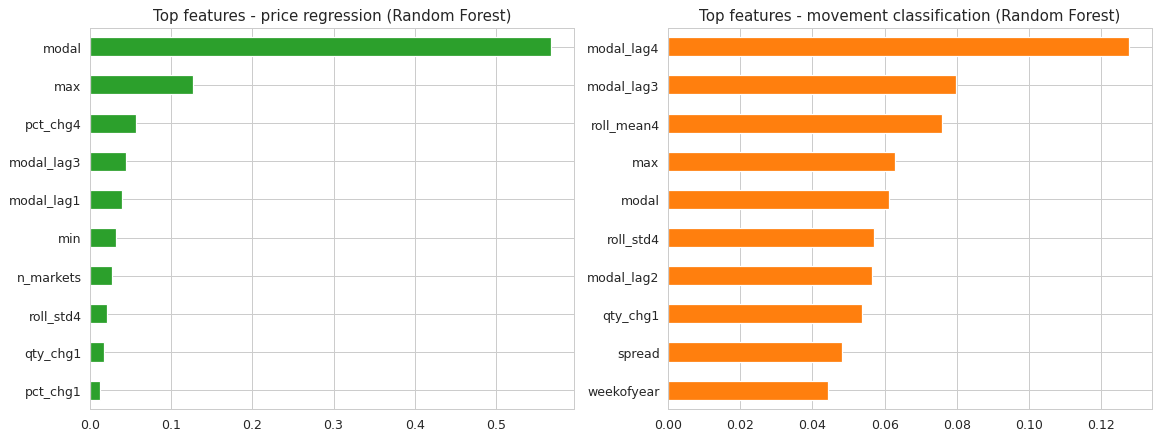

In [52]:
rf_reg = reg_models["Random Forest"].best_estimator_
rf_clf = clf_models["Random Forest"].best_estimator_

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
pd.Series(rf_reg.feature_importances_, index=FEATURES).sort_values().tail(10).plot(kind="barh", ax=ax[0], color="tab:green")
ax[0].set_title("Top features - price regression (Random Forest)")
pd.Series(rf_clf.feature_importances_, index=FEATURES).sort_values().tail(10).plot(kind="barh", ax=ax[1], color="tab:orange")
ax[1].set_title("Top features - movement classification (Random Forest)")
plt.tight_layout(); plt.show()

## 12. Illustrative forecast for the latest week
Using the best models to forecast the week after the last full week in the data (an illustration, not investment advice).

In [53]:
best_reg_model = reg_models[best_reg]
nxt_price = float(best_reg_model.predict(latest[FEATURES])[0])
best_clf_model = clf_models.get(best_clf, None)
if best_clf == "XGBoost":
    nxt_move = dec[int(xgb_clf.predict(latest[FEATURES])[0])]
else:
    nxt_move = best_clf_model.predict(latest[FEATURES])[0]
print("Last full week:", latest.index[0].date(), "| modal price index: ₹", round(float(latest.modal.iloc[0])))
print("Forecast for next week -> price: ₹", round(nxt_price), "| movement:", nxt_move)

Last full week: 2025-10-26 | modal price index: ₹ 7007
Forecast for next week -> price: ₹ 6980 | movement: Stable


## 13. Findings, limitations and future work

**Findings (test period Apr to Oct 2025: 61 training weeks, 29 test weeks)**
- **Regression:** the best model on the test period was **Linear Regression + Yeo-Johnson** (RMSE about ₹163/quintal, MAE about ₹121, R² 0.60), ahead of the naive "same as this week" forecast (RMSE about ₹194, MAE about ₹129, R² 0.44). The Yeo-Johnson transform improved plain Linear Regression (RMSE 172.8 to 163.1) and slightly improved Ridge, but made SVR slightly worse.
- **SVM:** SVR (RMSE about ₹240) was not competitive. SVC reached a macro F1 of 0.42, about the same as Logistic Regression (0.43), so SVM added nothing here.
- **Overfitting and underfitting:** Random Forest and XGBoost overfit (training RMSE about ₹71 and ₹40 against test RMSE about ₹245 and ₹230; training macro F1 of 0.96 and 1.00 against about 0.40 on the test weeks). Ridge was slightly underfit (its best `alpha`, 100, was the largest value tried). SVR overfit mildly. Linear Regression was the best-balanced fit.
- **Time-series cross-validation:** on the training period the naive forecast had a CV RMSE of about ₹88 (±43), and **no model beat it** (best: SVR + Yeo-Johnson about 92, Ridge + Yeo-Johnson about 93, Random Forest about 97; plain Linear Regression was unstable at about 830 ± 1,166). So the advantage of Linear Regression + Yeo-Johnson over the naive forecast seen on the test period is **not confirmed** by cross-validation. The evidence is limited, and the test result may partly depend on the chosen test period.
- **Classification:** Logistic Regression gave the best macro F1 (0.43 vs 0.18 for always predicting Stable; accuracy 45% vs 38%), with SVC (0.42), Random Forest (0.41) and XGBoost (0.40) close behind. Yeo-Johnson did not help the classifier (macro F1 0.39).
- **Price-spike alert:** the alert fired twice and was right both times (precision 1.00), but it caught only 2 of the 10 real rising weeks (recall 0.20). It is a cautious early-warning signal, not a complete spike detector.
- **Drivers:** the current price dominates the Random Forest regression (about 57% of the importance), followed by the weekly maximum price; for the movement classifier the lagged prices and the rolling mean matter most. Weekly arrivals add little (correlation with price is only about -0.17).

**Limitations**
- Only about 95 weeks of data and a 29-week test set, so the scores are noisy and can change with a different split or threshold.
- The "best" model was picked by its score on the test weeks, which is slightly optimistic; with more data a separate validation period should be used.
- The price is a state-level weekly index; weather, MSP and procurement policy, and national or international cotton prices are not modelled.
- One week (16 to 22 Dec 2024) had no price records at source and was interpolated (flagged in the data). No arrival records exist from June to early August 2024, so arrivals are set to 0 there.
- Market coverage changes over time (2 to 36 markets reporting a week), which the composition-adjusted index only partly removes.
- Lag 3 is already contained in the 4-week rolling mean, so it adds no new information.

**Future work**
- Add rice (paddy) and dry chilli, MSP and weather (rainfall, temperature) features, and more years of history.
- Try a wider Ridge grid, walk-forward validation, and probability-based alerts (for example alert when P(Rise) is above a chosen cut-off) to trade precision against recall.

## 14. Save the models for deployment (pickle)
The model is deployed as a small Streamlit app. This cell prepares everything the app needs in a folder called `deployment/`:
- `cotton_models.pkl`: the chosen regression model and classifier (each is a full pipeline with its scaler / Yeo-Johnson step inside), plus the feature list and the test-period scores.
- `weekly_history.csv`: the last 8 weekly rows, used by the app's "latest data" mode.
- `requirements.txt`: the package versions of **this** environment. A pickle only loads safely with the same scikit-learn version it was saved with, so the app must install these exact versions.

Only scikit-learn models are deployed (no XGBoost), so the app needs few packages. After the test-period evaluation, the two chosen models are **refitted on all 90 labelled weeks** (training + test) so the app uses the most recent data. The scores saved in the pickle are still the honest test-period scores of the models trained on the training weeks only.

Only unpickle files you created yourself or trust: a pickle can run code when it is loaded.

In [54]:
import pickle, sys
import importlib.metadata as md
from pathlib import Path

OUT = Path("deployment"); OUT.mkdir(exist_ok=True)

def fresh(model):
    """Unfitted copy of a model with its tuned settings."""
    return clone(model.best_estimator_) if hasattr(model, "best_estimator_") else clone(model)

# Only scikit-learn models are deployed (XGBoost would need an extra package)
dep_reg = reg_results.drop(["Naive baseline", "XGBoost"])["RMSE"].astype(float).idxmin()
dep_clf = clf_results.loc[list(clf_models), "F1 (macro)"].astype(float).idxmax()
print("Deploying:", dep_reg, "|", dep_clf)

reg_final = fresh(reg_models[dep_reg]).fit(data[FEATURES], data.next_price)
clf_final = fresh(clf_models[dep_clf]).fit(data[FEATURES], data.move)

alert_p = clf_pred[dep_clf] == "Rise"
alert_t = y_test_c.values == "Rise"
hits = int((alert_p & alert_t).sum())

bundle = {
    "reg_model": reg_final, "clf_model": clf_final,
    "reg_name": dep_reg, "clf_name": dep_clf,
    "features": FEATURES, "threshold": THRESHOLD, "classes": list(clf_final.classes_),
    "trained_until": str(data.index.max().date()), "n_weeks": len(data),
    "test_metrics": {
        "reg": reg_results.loc[dep_reg].to_dict(),
        "naive": reg_results.loc["Naive baseline"].to_dict(),
        "clf": clf_results.loc[dep_clf].to_dict(),
        "majority": clf_results.loc["Majority baseline"].to_dict(),
        "alerts_raised": int(alert_p.sum()), "alerts_correct": hits, "rise_weeks_in_test": int(alert_t.sum()),
    },
}
with open(OUT / "cotton_models.pkl", "wb") as fh:
    pickle.dump(bundle, fh)

weekly[["p_modal", "p_min", "p_max", "qty", "n_markets", "interpolated"]].tail(8).round(2).to_csv(OUT / "weekly_history.csv")

def pin(pkg):
    try:
        return f"{pkg}=={md.version(pkg)}"
    except md.PackageNotFoundError:
        return pkg
(OUT / "requirements.txt").write_text("\n".join(pin(p) for p in ["streamlit", "scikit-learn", "pandas", "numpy"]) + "\n")

print("Python", sys.version.split()[0])
print((OUT / "requirements.txt").read_text())

# Quick check: reload the pickle and predict for the latest week
with open(OUT / "cotton_models.pkl", "rb") as fh:
    check = pickle.load(fh)
print("Reloaded OK ->", check["reg_name"], "predicts", round(float(check["reg_model"].predict(latest[FEATURES])[0])),
      "|", check["clf_name"], "predicts", check["clf_model"].predict(latest[FEATURES])[0])

Deploying: Linear Regression + Yeo-Johnson | Logistic Regression
Python 3.12.3
streamlit==1.66.1
scikit-learn==1.8.0
pandas==3.0.2
numpy==2.4.4

Reloaded OK -> Linear Regression + Yeo-Johnson predicts 7090 | Logistic Regression predicts Rise
